## Análise Exploratória dos Dados

Esta etapa tem como objetivo realizar uma análise exploratória inicial do conjunto de dados de chamados, buscando compreender sua estrutura, distribuição das variáveis e possíveis relações entre os atributos.

A análise também busca identificar características relevantes para a etapa posterior de desenvolvimento do modelo de IA, tendo como variável alvo a categoria do chamado (`target_category`).

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/clean/chamados-clean.csv')

print(f'Linhas: {df.shape[0]}')
print(f'Colunas: {df.shape[1]}')

df.head()

Linhas: 5000
Colunas: 44


,ticket_id,created_at,customer_id,department,city_x,state_x,device_type,os,browser,network_type,...,vip,monthly_revenue,num_events,last_event_date,event_types,num_abertura,num_updates,num_encerramento,num_images_y,target_category
0,1,2025-01-01T00:17:00,5012,Operações,Campinas,BA,Desktop,Windows,Safari,WiFi,...,NaN,NaN,0,NaN,NaN,0,0,0,NaN,Hardware
1,2,2025-01-01T00:34:00,6574,Financeiro,Campinas,RJ,Notebook,Windows,Chrome,5G,...,NaN,NaN,0,NaN,NaN,0,0,0,NaN,RH
2,3,2025-01-01T00:51:00,2139,TI,Campinas,MG,Desktop,Linux,Chrome,5G,...,NaN,NaN,0,NaN,NaN,0,0,0,NaN,Financeiro
3,4,2025-01-01T01:08:00,7216,Financeiro,Belo Horizonte,RJ,Mobile,Android,Chrome,Cabo,...,NaN,NaN,0,NaN,NaN,0,0,0,NaN,Software
4,5,2025-01-01T01:25:00,5040,Financeiro,Belo Horizonte,PR,Mobile,iOS,Edge,Cabo,...,NaN,NaN,0,NaN,NaN,0,0,0,NaN,Rede


### 1. Visão geral do dataset

Inicialmente, será realizada uma análise geral do conjunto de dados,
considerando sua dimensão, tipos de dados, valores ausentes e estatísticas
descritivas. Essa etapa permite identificar as principais características
do dataset antes da análise das variáveis relacionadas à classificação
dos chamados.

In [3]:
print("Dimensões do dataset:")
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

print("\nTipos de dados:")
print(df.dtypes.value_counts())

print("\nValores ausentes:")
print(df.isna().sum().sort_values(ascending=False).head(15))

Dimensões do dataset:
Linhas: 5000
Colunas: 44

Tipos de dados:
str        22
int64      14
float64     8
Name: count, dtype: int64

Valores ausentes:
last_event_date       5000
event_types           5000
num_images_y          5000
monthly_revenue       4998
contract_type         4998
employees             4998
city_y                4998
segment               4998
company               4998
vip                   4998
customer_since        4998
state_y               4998
sla_hours                0
historical_tickets       0
network_type             0
dtype: int64


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ticket_id,5000.0,NaN,NaN,NaN,2500.5,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
created_at,5000,5000,2025-01-01T00:17:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,5000.0,NaN,NaN,NaN,5517.1506,2627.870259,1006.0,3171.0,5540.0,7813.25,9999.0
department,5000,4,RH,1274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_x,5000,5,Santos,1012,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state_x,5000,6,RS,862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_type,5000,3,Desktop,1684,NaN,NaN,NaN,NaN,NaN,NaN,NaN
os,5000,4,Windows,1256,NaN,NaN,NaN,NaN,NaN,NaN,NaN
browser,5000,4,Safari,1302,NaN,NaN,NaN,NaN,NaN,NaN,NaN
network_type,5000,4,Cabo,1296,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df['target_category'].value_counts()

target_category
Software      892
Rede          861
Hardware      835
RH            821
Acesso        821
Financeiro    770
Name: count, dtype: int64

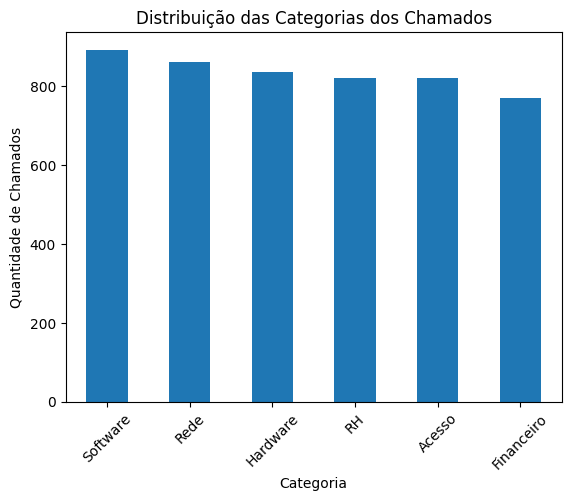

In [6]:
df['target_category'].value_counts().plot(kind='bar')

plt.title('Distribuição das Categorias dos Chamados')
plt.xlabel('Categoria')
plt.ylabel('Quantidade de Chamados')
plt.xticks(rotation=45)
plt.show()

Por enquanto tem bastante células vazias (5000) ou quase vazias (4998), vai mudar depois da limpeza

### 2. Distribuição da variável alvo

A variável `target_category` representa a categoria final atribuída a cada chamado e será utilizada como variável alvo no problema de classificação.

A distribuição das categorias é relativamente equilibrada. A categoria mais frequente é `Software`, com 892 registros, enquanto `Financeiro` apresenta a menor quantidade, com 770 registros.

Essa distribuição é relevante para o desenvolvimento do modelo de Inteligência Artificial, pois não há, inicialmente, uma diferença extrema na quantidade de exemplos entre as classes.

In [7]:
# Distribuição percentual das categorias
distribuicao = (
    df['target_category']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

distribuicao

target_category
Software      17.84
Rede          17.22
Hardware      16.70
RH            16.42
Acesso        16.42
Financeiro    15.40
Name: proportion, dtype: float64

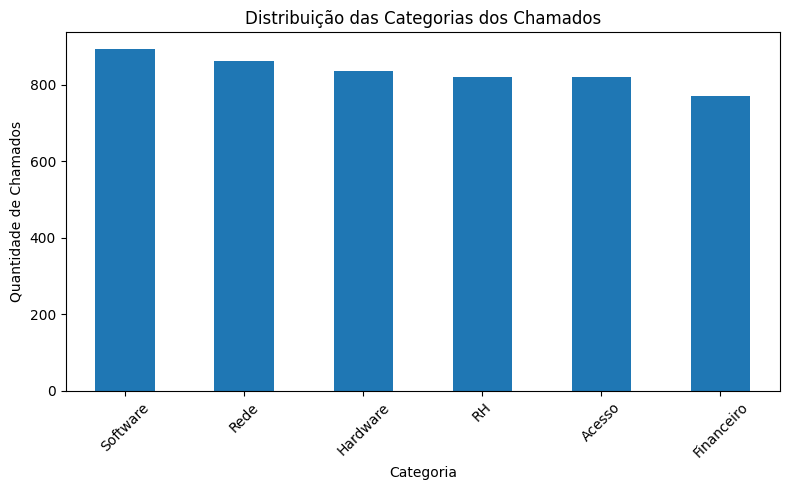

In [8]:
# Gráfico da distribuição das categorias

df['target_category'].value_counts().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Distribuição das Categorias dos Chamados')
plt.xlabel('Categoria')
plt.ylabel('Quantidade de Chamados')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 3. Testando correlação entre colunas

In [9]:
pd.crosstab(
    df['priority'],
    df['target_category']
)

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
priority,,,,,,
Alta,176,180,205,193,226,235
Baixa,236,221,209,200,188,206
Crítica,192,201,213,216,232,223
Média,217,168,208,212,215,228


In [10]:
pd.crosstab(
    df['target_category'],
    df['priority'],
    normalize='index'
).round(3)

priority,Alta,Baixa,Crítica,Média
target_category,,,,
Acesso,0.214,0.287,0.234,0.264
Financeiro,0.234,0.287,0.261,0.218
Hardware,0.246,0.250,0.255,0.249
RH,0.235,0.244,0.263,0.258
Rede,0.262,0.218,0.269,0.250
Software,0.263,0.231,0.250,0.256


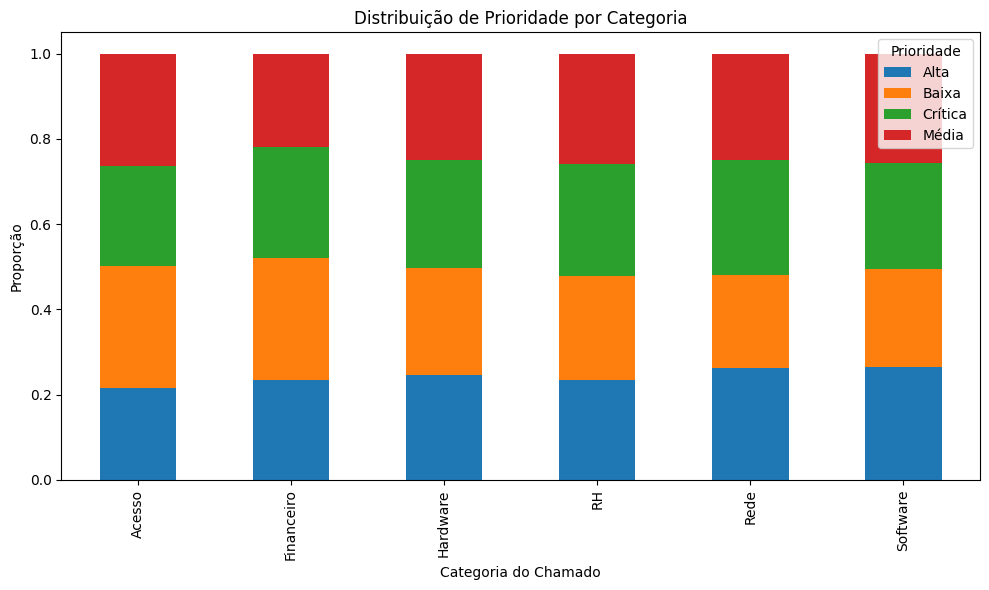

In [11]:
pd.crosstab(
    df['target_category'],
    df['priority'],
    normalize='index'
).plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Distribuição de Prioridade por Categoria')
plt.xlabel('Categoria do Chamado')
plt.ylabel('Proporção')
plt.legend(title='Prioridade')
plt.tight_layout()
plt.show()

A distribuição das prioridades apresenta algumas diferenças entre as categorias dos chamados, porém sem uma concentração extremamente elevada em uma única prioridade. A categoria `Hardware`, por exemplo, apresenta uma distribuição bastante uniforme entre as quatro prioridades.

As categorias `Acesso` e `Financeiro` apresentam maior proporção de chamados com prioridade `Baixa`, enquanto `Rede` apresenta uma proporção relativamente maior de chamados com prioridade `Crítica`. Já `Software` possui maior participação de chamados com prioridade `Alta`.

De forma geral, a variável `priority` apresenta possíveis diferenças de distribuição entre as categorias, mas não aparenta possuir, isoladamente, uma relação determinística com a variável alvo. Essa relação poderá ser investigada posteriormente por meio de testes estatísticos e pelo desempenho das variáveis durante o treinamento do modelo de classificação.


In [12]:
pd.crosstab(
    df['target_category'],
    df['department']
)

department,Financeiro,Operações,RH,TI
target_category,,,,
Acesso,201,209,213,198
Financeiro,190,175,204,201
Hardware,221,205,219,190
RH,197,196,211,217
Rede,205,226,194,236
Software,210,218,233,231


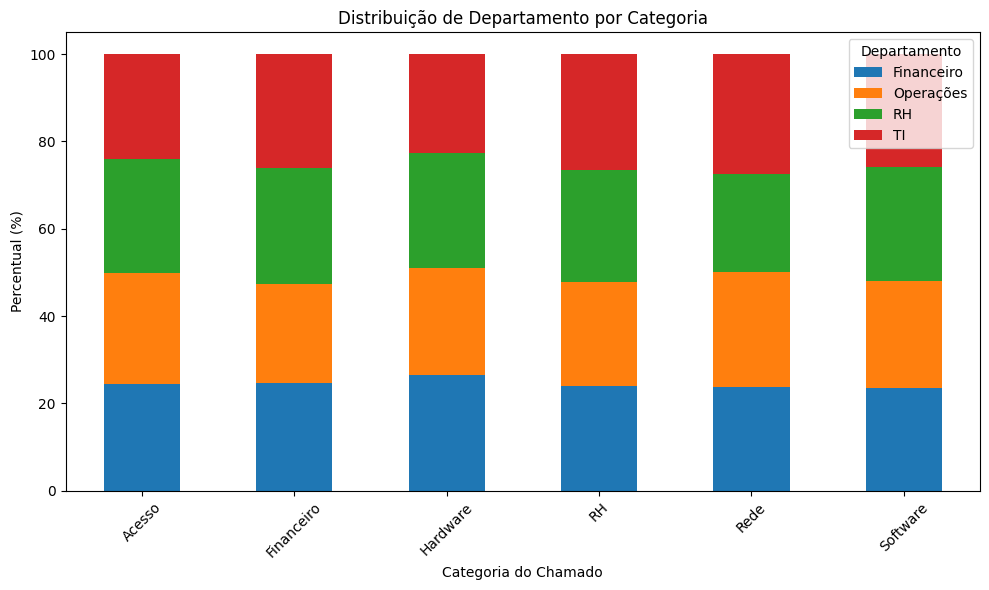

In [13]:
pd.crosstab(
    df['target_category'],
    df['department'],
    normalize='index'
).mul(100).plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Distribuição de Departamento por Categoria')
plt.xlabel('Categoria do Chamado')
plt.ylabel('Percentual (%)')
plt.xticks(rotation=45)
plt.legend(title='Departamento')
plt.tight_layout()
plt.show()

A relação entre `department` e `target_category` apresenta uma distribuição relativamente equilibrada entre os diferentes departamentos. Apesar de algumas diferenças pontuais, como a maior quantidade de chamados da categoria `Rede` no departamento de TI e de chamados de `Software` no departamento de RH, não foi observada uma concentração dominante de uma categoria em um único departamento.

Dessa forma, a variável `department` apresenta potencial para contribuir com a classificação dos chamados, mas não aparenta ser suficiente, isoladamente, para determinar a categoria do chamado. Sua importância poderá ser avaliada posteriormente durante o treinamento e a análise do modelo de Inteligência Artificial.


In [14]:
pd.crosstab(
    df['target_category'],
    df['device_type']
)

device_type,Desktop,Mobile,Notebook
target_category,,,
Acesso,258,276,287
Financeiro,256,271,243
Hardware,295,264,276
RH,292,264,265
Rede,290,295,276
Software,293,313,286


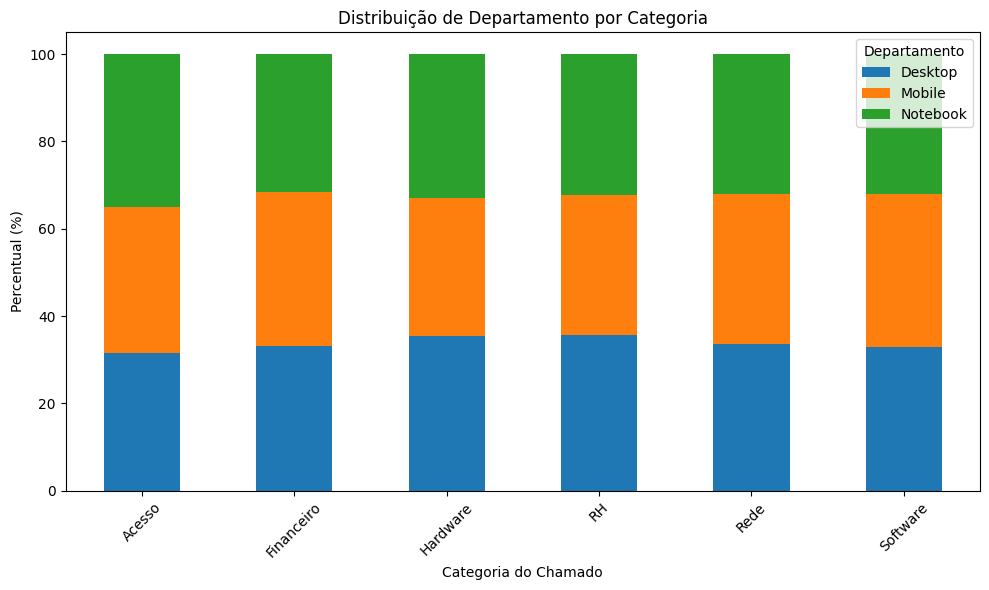

In [15]:
pd.crosstab(
    df['target_category'],
    df['device_type'],
    normalize='index'
).mul(100).plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Distribuição de Departamento por Categoria')
plt.xlabel('Categoria do Chamado')
plt.ylabel('Percentual (%)')
plt.xticks(rotation=45)
plt.legend(title='Departamento')
plt.tight_layout()
plt.show()

A variável `device_type` apresenta três categorias principais: Desktop, Mobile e Notebook. A distribuição dos tipos de dispositivo entre as diferentes categorias de chamados é relativamente equilibrada.

Algumas diferenças podem ser observadas, como a maior quantidade de chamados de `Hardware` associados a Desktop e de chamados de `Rede` e `Software` associados a Mobile. Entretanto, essas diferenças não são suficientemente acentuadas para indicar uma relação determinística entre o tipo de dispositivo e a categoria do chamado.

Assim, `device_type` pode apresentar alguma contribuição para a classificação dos chamados, mas sua capacidade preditiva deverá ser avaliada em conjunto com as demais variáveis durante o treinamento do modelo de Inteligência Artificial.


In [16]:
pd.crosstab(
    df['target_category'],
    df['status']
)

status,Aberto,Em andamento,Fechado
target_category,,,
Acesso,281,275,265
Financeiro,249,259,262
Hardware,300,257,278
RH,277,274,270
Rede,264,309,288
Software,318,280,294


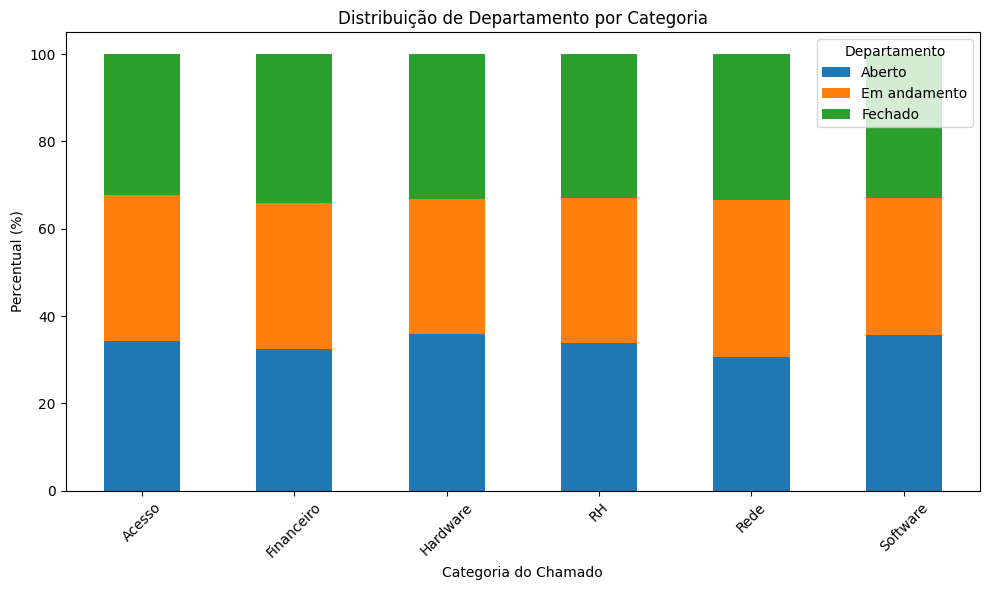

In [17]:
pd.crosstab(
    df['target_category'],
    df['status'],
    normalize='index'
).mul(100).plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Distribuição de Departamento por Categoria')
plt.xlabel('Categoria do Chamado')
plt.ylabel('Percentual (%)')
plt.xticks(rotation=45)
plt.legend(title='Departamento')
plt.tight_layout()
plt.show()

A variável `status` apresenta três categorias: Aberto, Em andamento e Fechado. A distribuição dos status entre as diferentes categorias de chamados é relativamente equilibrada.

Algumas diferenças podem ser observadas. A categoria `Hardware` apresenta maior quantidade de chamados com status `Aberto`, enquanto `Rede` possui maior quantidade de chamados `Em andamento`. A categoria `Software` também apresenta uma quantidade relativamente elevada de chamados `Abertos`.

Apesar dessas diferenças, não foi observada uma concentração suficientemente forte para indicar que o status, isoladamente, determine a categoria do chamado. Portanto, essa variável poderá contribuir para o modelo de classificação, mas sua relevância deverá ser avaliada em conjunto com as demais características do dataset.


In [18]:
df.groupby('target_category')['sentiment_score'].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

,mean,median,min,max
target_category,,,,
Acesso,0.00,0.01,-1.0,1.0
Financeiro,-0.04,-0.04,-1.0,1.0
Hardware,-0.01,0.00,-1.0,1.0
RH,0.00,0.03,-1.0,1.0
Rede,-0.00,-0.02,-1.0,1.0
Software,0.02,0.03,-1.0,1.0


A variável `sentiment_score` apresenta valores entre -1 e 1 e foi analisada considerando a média, mediana, mínimo e máximo de cada categoria de chamado.

As médias apresentaram valores muito próximos entre as categorias, variando de -0,04 em `Financeiro` a 0,02 em `Software`. As medianas também permaneceram próximas de zero.

Esse comportamento indica que, inicialmente, não há uma diferença evidente no sentimento médio entre as categorias dos chamados. Portanto, o `sentiment_score` não aparenta apresentar uma relação forte com a variável alvo quando analisado isoladamente.

Apesar disso, a variável não deve ser descartada nesta etapa, pois sua contribuição poderá ser avaliada posteriormente durante o treinamento do modelo de classificação e em conjunto com outras características.


In [19]:
df.groupby('target_category')['resolution_time_hours'].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

,mean,median,min,max
target_category,,,,
Acesso,34.71,35.0,1,72
Financeiro,35.79,34.0,1,72
Hardware,36.68,37.0,1,72
RH,36.03,36.0,1,72
Rede,36.32,37.0,1,72
Software,36.56,35.0,1,72


A variável `resolution_time_hours` representa o tempo necessário para a resolução dos chamados, em horas. A análise por categoria mostra médias bastante próximas, variando de 34,71 horas para `Acesso` a 36,68 horas para `Hardware`.

A maior diferença entre as médias das categorias é de aproximadamente 1,97 hora. Além disso, todas as categorias apresentam valores entre 1 e 72 horas.

Dessa forma, não foi observada uma diferença expressiva no tempo médio de resolução entre as categorias. Embora essa variável possa fornecer alguma informação ao modelo, sua relação isolada com `target_category` aparenta ser limitada.

Também é importante considerar o momento em que o modelo será utilizado. Caso o objetivo seja prever a categoria no momento da abertura do chamado, `resolution_time_hours` pode representar uma forma de vazamento de informação, pois o tempo de resolução só é conhecido após o atendimento. Essa questão deverá ser avaliada antes da seleção final das variáveis para o modelo.


In [20]:
df.corr(numeric_only=True).round(2)

,ticket_id,customer_id,historical_tickets,sla_hours,resolution_time_hours,image_width,image_height,has_attachment,sentiment_score,num_words,...,longitude,employees,monthly_revenue,num_events,last_event_date,event_types,num_abertura,num_updates,num_encerramento,num_images_y
ticket_id,1.00,0.01,0.02,-0.02,-0.01,0.00,0.00,0.01,0.01,0.01,...,-0.01,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,0.01,1.00,-0.01,-0.01,-0.00,0.01,0.00,-0.01,-0.01,-0.00,...,0.01,-1.0,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
historical_tickets,0.02,-0.01,1.00,-0.02,0.02,-0.01,0.03,0.00,-0.00,-0.01,...,-0.01,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sla_hours,-0.02,-0.01,-0.02,1.00,-0.01,-0.01,0.01,0.00,0.01,0.01,...,-0.01,-1.0,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
resolution_time_hours,-0.01,-0.00,0.02,-0.01,1.00,-0.01,-0.00,0.01,0.01,-0.01,...,0.00,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_width,0.00,0.01,-0.01,-0.01,-0.01,1.00,0.32,0.00,-0.01,0.01,...,-0.02,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_height,0.00,0.00,0.03,0.01,-0.00,0.32,1.00,-0.01,0.00,0.01,...,0.01,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_attachment,0.01,-0.01,0.00,0.00,0.01,0.00,-0.01,1.00,-0.01,0.01,...,-0.03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sentiment_score,0.01,-0.01,-0.00,0.01,0.01,-0.01,0.00,-0.01,1.00,-0.01,...,-0.03,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_words,0.01,-0.00,-0.01,0.01,-0.01,0.01,0.01,0.01,-0.01,1.00,...,0.02,-1.0,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4. Heatmap

In [21]:
colunas_numericas = [
    'historical_tickets',
    'sla_hours',
    'resolution_time_hours',
    'image_width',
    'image_height',
    'has_attachment',
    'sentiment_score',
    'num_words',
    'num_images_x',
    'latitude',
    'longitude'
]

correlacoes = df[colunas_numericas].corr().round(2)

correlacoes

,historical_tickets,sla_hours,resolution_time_hours,image_width,image_height,has_attachment,sentiment_score,num_words,num_images_x,latitude,longitude
historical_tickets,1.00,-0.02,0.02,-0.01,0.03,0.00,-0.00,-0.01,0.01,-0.01,-0.01
sla_hours,-0.02,1.00,-0.01,-0.01,0.01,0.00,0.01,0.01,0.01,-0.01,-0.01
resolution_time_hours,0.02,-0.01,1.00,-0.01,-0.00,0.01,0.01,-0.01,0.01,-0.02,0.00
image_width,-0.01,-0.01,-0.01,1.00,0.32,0.00,-0.01,0.01,-0.01,-0.01,-0.02
image_height,0.03,0.01,-0.00,0.32,1.00,-0.01,0.00,0.01,0.01,0.00,0.01
has_attachment,0.00,0.00,0.01,0.00,-0.01,1.00,-0.01,0.01,0.00,0.02,-0.03
sentiment_score,-0.00,0.01,0.01,-0.01,0.00,-0.01,1.00,-0.01,0.00,0.01,-0.03
num_words,-0.01,0.01,-0.01,0.01,0.01,0.01,-0.01,1.00,-0.01,0.00,0.02
num_images_x,0.01,0.01,0.01,-0.01,0.01,0.00,0.00,-0.01,1.00,-0.01,0.01
latitude,-0.01,-0.01,-0.02,-0.01,0.00,0.02,0.01,0.00,-0.01,1.00,-0.00


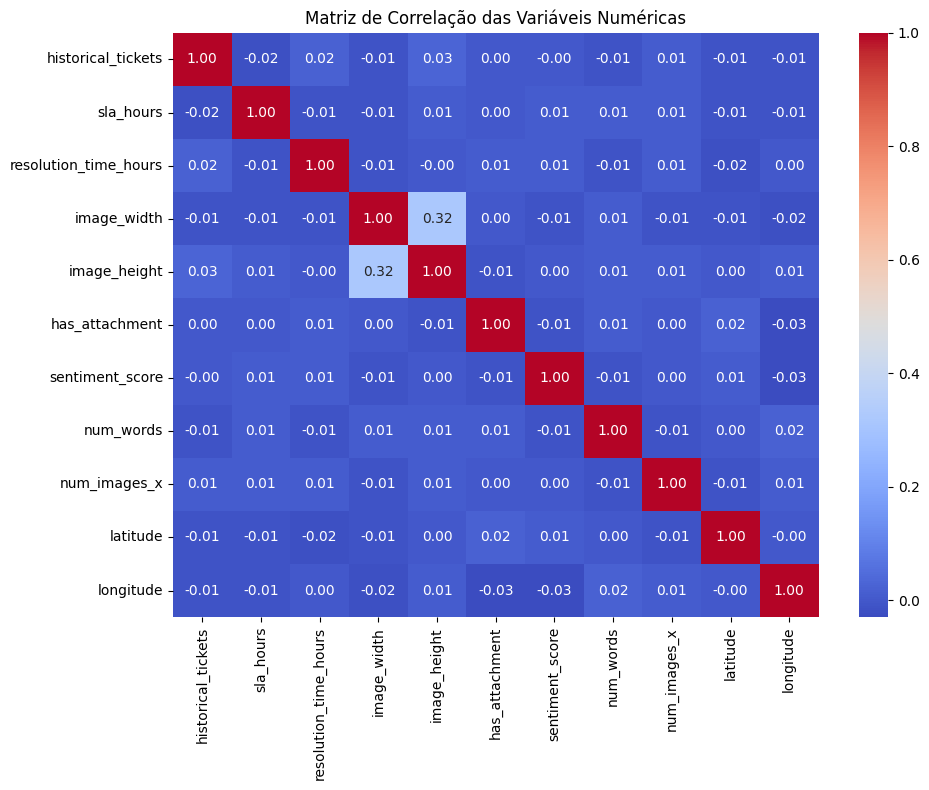

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlacoes,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de Correlação das Variáveis Numéricas')
plt.tight_layout()
plt.show()

### Análise das correlações

A matriz de correlação foi utilizada para verificar possíveis relações lineares entre as principais variáveis numéricas do conjunto de dados. De modo geral, foram observadas correlações próximas de zero entre a maioria das variáveis, indicando baixa relação linear entre elas.

A maior correlação observada ocorreu entre `image_width` e `image_height`, com valor de aproximadamente 0,32. Essa relação pode ser explicada pela própria característica das imagens, uma vez que suas dimensões tendem a variar conjuntamente.

As demais variáveis apresentaram correlações muito baixas. Também não foi identificada uma correlação linear relevante entre `sentiment_score` e `resolution_time_hours`, indicando que, neste conjunto de dados, o sentimento registrado não apresenta uma relação linear evidente com o tempo necessário para resolução.

É importante destacar que a matriz de correlação considera apenas relações entre variáveis numéricas e, portanto, não permite determinar diretamente quais atributos possuem maior relação com a variável alvo `target_category`. Essa análise será complementada posteriormente durante o desenvolvimento e avaliação do modelo de classificação.


### 5. Análise dos Textos

In [23]:
# Quantidade de caracteres
df['title_chars'] = df['title'].fillna('').str.len()
df['description_chars'] = df['description'].fillna('').str.len()

# Quantidade de palavras
df['title_words'] = df['title'].fillna('').str.split().str.len()
df['description_words'] = df['description'].fillna('').str.split().str.len()

df[
    [
        'title_chars',
        'description_chars',
        'title_words',
        'description_words'
    ]
].describe().round(2)

,title_chars,description_chars,title_words,description_words
count,5000.00,5000.00,5000.00,5000.00
mean,53.64,54.45,8.81,8.90
std,7.62,8.99,1.47,1.59
min,29.00,29.00,5.00,5.00
25%,48.00,48.00,8.00,8.00
50%,54.00,54.00,9.00,9.00
75%,63.00,61.00,10.00,10.00
max,63.00,85.00,13.00,15.00


As variáveis `title` e `description` foram analisadas considerando a quantidade de caracteres e palavras presentes em cada registro.

Os títulos possuem, em média, 8,81 palavras e 53,64 caracteres, enquanto as descrições apresentam média de 8,90 palavras e 54,45 caracteres. As medianas são de 9 palavras para ambas as variáveis.

Os textos apresentam uma variação relativamente pequena de tamanho, com títulos entre 5 e 13 palavras e descrições entre 5 e 15 palavras. Dessa forma, não foram identificados textos excessivamente longos ou curtos no conjunto analisado.

Como `title` e `description` contêm informações textuais relacionadas ao chamado, essas variáveis apresentam potencial para contribuir para a classificação de `target_category`. Na próxima etapa, será analisada a frequência das palavras presentes nos textos e sua distribuição entre as diferentes categorias.


In [24]:
textos = (
    df['title'].fillna('') + ' ' +
    df['description'].fillna('')
)

palavras = textos.str.lower().str.split().explode()

palavras.value_counts().head(20)

de           6240
o            6154
ao           4314
não          3203
sistema      3122
falha        2940
no           2320
tentar       1732
durante      1698
erro         1602
apresenta    1577
usuário      1358
e            1306
a            1302
dados.       1166
tela         1114
problema     1016
exibe         996
gerar         992
está          976
Name: count, dtype: int64

In [25]:
stopwords = {
    'a', 'o', 'as', 'os', 'um', 'uma', 'uns', 'umas',
    'de', 'do', 'da', 'dos', 'das',
    'em', 'no', 'na', 'nos', 'nas',
    'por', 'para', 'com', 'sem',
    'e', 'ou', 'mas',
    'ao', 'aos',
    'que', 'se',
    'é', 'está', 'estao', 'não',
    'como', 'mais', 'menos',
    'durante'
}

palavras_filtradas = palavras[
    ~palavras.isin(stopwords)
]

palavras_filtradas.value_counts().head(20)

sistema       3122
falha         2940
tentar        1732
erro          1602
apresenta     1577
usuário       1358
dados.        1166
tela          1114
problema      1016
exibe          996
gerar          992
relatório.     786
acesso         766
abrir          703
fazer          702
acessar        674
fica           670
consegue       662
devido         662
executar       647
Name: count, dtype: int64

In [26]:
for categoria in df['target_category'].unique():
    textos_categoria = (
        df.loc[df['target_category'] == categoria, 'title'].fillna('') + ' ' +
        df.loc[df['target_category'] == categoria, 'description'].fillna('')
    )

    palavras_categoria = textos_categoria.str.lower().str.split().explode()

    palavras_categoria = palavras_categoria[
        ~palavras_categoria.isin(stopwords)
    ]

    print(f'\n--- {categoria} ---')
    print(palavras_categoria.value_counts().head(10))


--- Hardware ---
apresenta           432
falha               416
problema            366
hardware:           366
usuário             362
relatou             362
tela                348
responde            334
exibe               334
inesperadamente.    307
Name: count, dtype: int64

--- RH ---
sistema      1130
apresenta     432
erro          430
falha         394
tentar        338
rh:           318
usuário       302
consegue      302
devido        302
folha         232
Name: count, dtype: int64

--- Financeiro ---
financeiro     594
sistema        564
módulo         452
falha          440
erro           436
gerar          433
relatório.     347
financeiro:    328
exibe          312
relatório      286
Name: count, dtype: int64

--- Software ---
sistema            910
falha              474
erro               444
apresenta          434
tentar             402
exibe              350
aplicativo         346
fecha              346
inesperadamente    346
quando             328
Name: count, d

Foi realizada uma análise das palavras mais frequentes nos campos `title` e `description`, considerando cada categoria de chamado separadamente.

Os resultados mostram a presença de vocabulário característico entre as categorias. Em `Hardware`, destacam-se termos como `hardware`, `tela`, `falha` e `problema`. Em `RH`, aparecem termos como `rh`, `folha`, `sistema` e `erro`. Na categoria `Financeiro`, destacam-se `financeiro`, `módulo`, `relatório` e `gerar`. Em `Software`, aparecem com maior frequência termos como `aplicativo`, `fecha`, `erro` e `sistema`. Já em `Rede`, destacam-se `rede`, `conectividade`, `acesso` e `instável`. Na categoria `Acesso`, são frequentes termos como `usuário`, `acesso`, `bloqueado` e `acessar`.

Esse comportamento indica que os campos textuais possuem informações potencialmente relevantes para a classificação de `target_category`, tornando técnicas de processamento de linguagem natural, como TF-IDF, candidatas para a etapa de modelagem.

Entretanto, também foi identificada a presença de termos que fazem referência diretamente às próprias categorias, como `hardware`, `rh`, `financeiro` e `rede`. Como os textos do dataset foram construídos a partir de templates relacionados às categorias, essa característica deve ser considerada durante o desenvolvimento do modelo, pois pode provocar vazamento de informação e resultar em uma avaliação artificialmente elevada do desempenho.

Assim, durante a preparação dos dados para a Inteligência Artificial, será necessário avaliar se esses termos devem ser removidos ou se o modelo deve ser treinado com os textos originais, considerando o objetivo real da classificação.


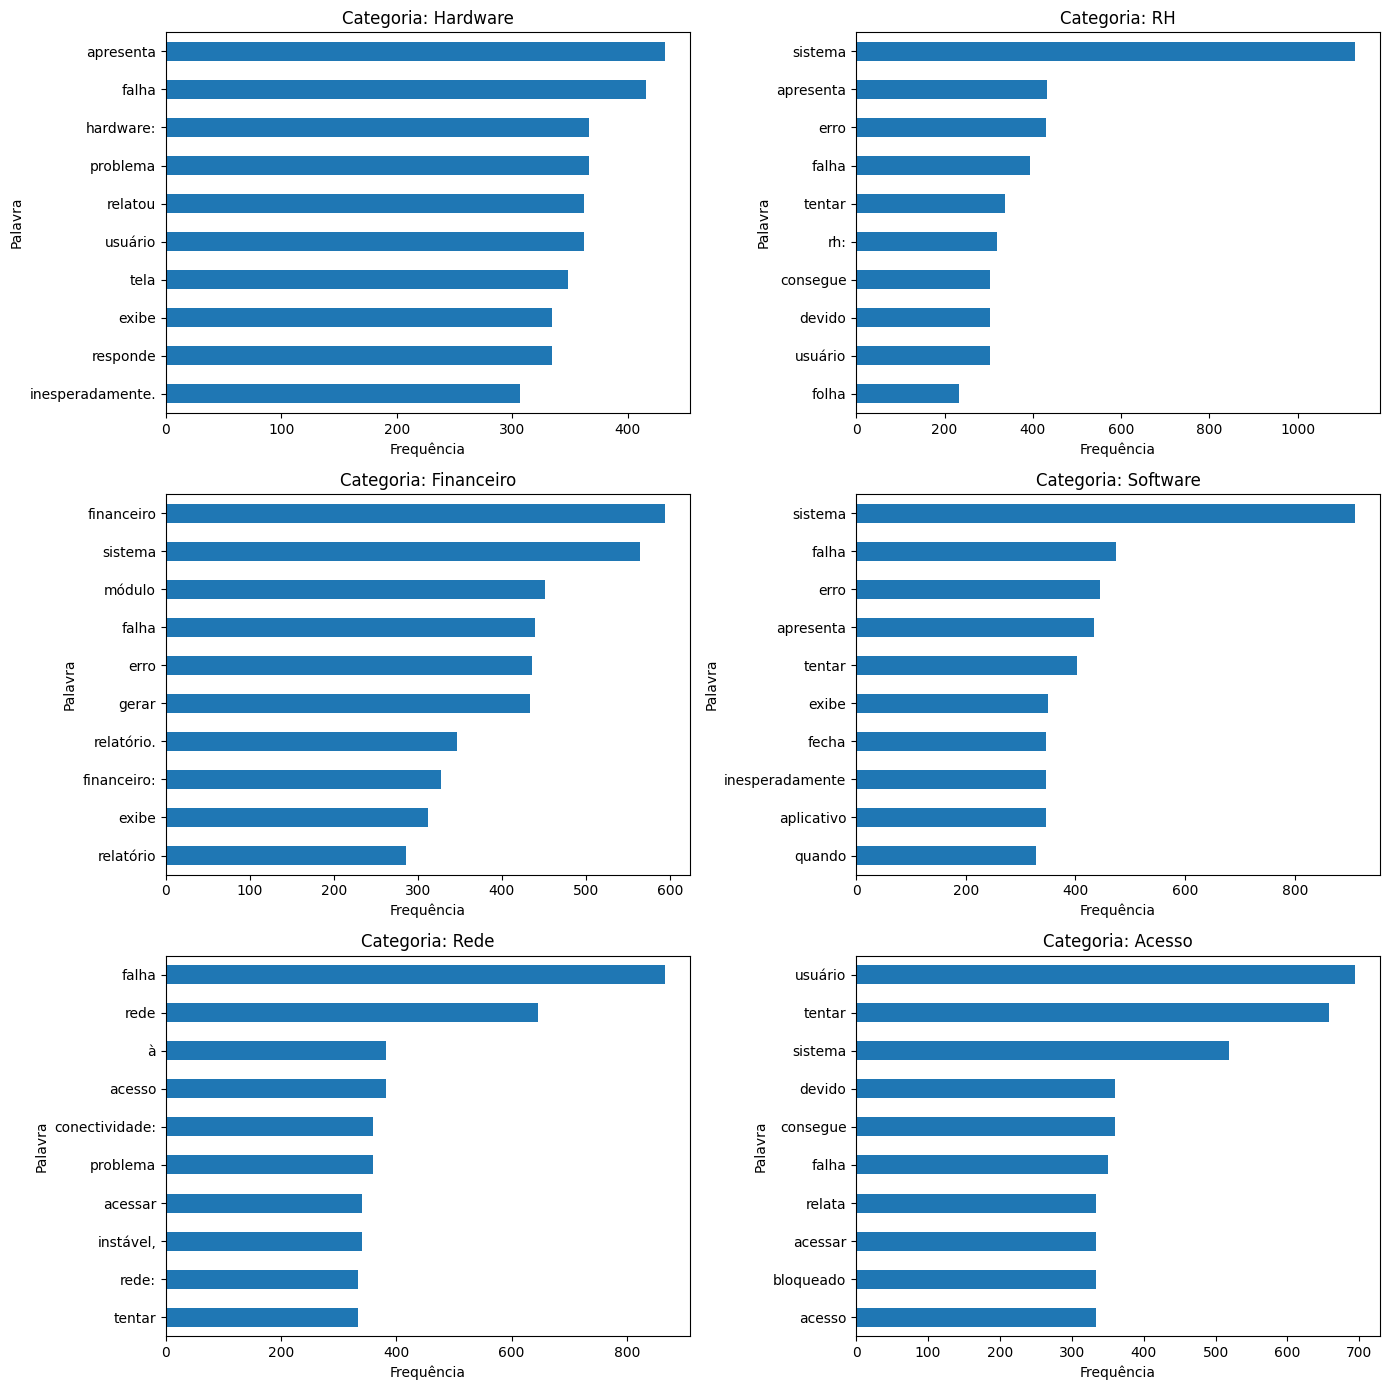

In [28]:
fig, axes = plt.subplots(3, 2, figsize=(14, 14))

for ax, categoria in zip(axes.flatten(), df['target_category'].unique()):

    textos_categoria = (
        df.loc[df['target_category'] == categoria, 'title'].fillna('') + ' ' +
        df.loc[df['target_category'] == categoria, 'description'].fillna('')
    )

    palavras_categoria = textos_categoria.str.lower().str.split().explode()

    palavras_categoria = palavras_categoria[
        ~palavras_categoria.isin(stopwords)
    ]

    frequencia = palavras_categoria.value_counts().head(10)

    frequencia.sort_values().plot(
        kind='barh',
        ax=ax
    )

    ax.set_title(f'Categoria: {categoria}')
    ax.set_xlabel('Frequência')
    ax.set_ylabel('Palavra')

plt.tight_layout()
plt.show()